# Лабораторна робота 3 — герметизація конвеєра і надійна валідація

| Розділ | Крок ТЗ |
|---|---|
| 1. DVC lineage | 4.1 |
| 2. Механізм витоку ЛР2 (теорія) | 4.2, ч. 1 |
| 3. Герметичний конвеєр: imblearn, відбір у фолдах, вибір ланки | 4.3 |
| 4. Вкладена CV + Optuna, аудиторський слід по фолдах | 4.4 |
| 5. Cost-sensitive: матриця втрат, class_weight, поріг | 4.5 |
| 6. Статистична перевірка різниці (McNemar) | 4.2, ч. 3 — виконується останньою |
| 7. Фінальна модель для ЛР4–5 | — |

Справедливість (Крок 6) — у `lab3_fairness.ipynb`. **Дані читаються лише через DVC API** (`src/data.py::open_data`).


In [1]:
import sys, os, json, subprocess, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, f1_score

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
REPORTS = ROOT / "reports"
ACCENT, SECOND, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d0cfca", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "legend.frameon": False,
})
from src.data import load_data_config, read_processed, read_bytes
from src.prepare_data import load_hermetic_config
from src.evaluation import load_yaml
dc, hc, costs = load_data_config(), load_hermetic_config(), load_yaml("config/costs.yaml")
CONFIG = {"LR": "config/generated/config_lr_hermetic.yaml", "RF": "config/generated/config_rf_hermetic.yaml"}

## 1. DVC lineage (п. 4.1)

In [2]:
import hashlib, yaml
ptr = yaml.safe_load((ROOT / "data/raw/E Commerce Dataset.xlsx.dvc").read_text(encoding="utf-8"))["outs"][0]
md5 = hashlib.md5(read_bytes("data/raw/E Commerce Dataset.xlsx")).hexdigest()   # вміст, прочитаний через dvc.api
print(f"md5 у .dvc-покажчику: {ptr['md5']}\nmd5 вмісту (dvc.api):  {md5}\nзбіг: {md5 == ptr['md5']}")
status = subprocess.run([str(ROOT / ".venv/Scripts/dvc.exe"), "status"], capture_output=True, text=True, cwd=ROOT)
print("\n$ dvc status\n" + (status.stdout or status.stderr).strip())

md5 у .dvc-покажчику: 3586e9c1cb117a645b062deae6a961c2
md5 вмісту (dvc.api):  3586e9c1cb117a645b062deae6a961c2
збіг: True


$ dvc status
Data and pipelines are up to date.

In [3]:
lock = yaml.safe_load((ROOT / "dvc.lock").read_text(encoding="utf-8"))["stages"]["prepare"]
pd.DataFrame([{"output": o["path"], "md5": o["md5"], "size": o["size"]} for o in lock["outs"]])

,output,md5,size
0,data/processed/dfs_columns.json,fa22dfd34a8af312cb57206dc77c404e,3738
1,data/processed/holdout.csv,ab601b00cd06d4746409a441404d753a,2014815
2,data/processed/reviews_linked.csv,0a8c107257693ba68e929b00cd7ee74a,5540971
3,data/processed/train.csv,df967ac5608cff85b3db0bb7a1722284,8127919


In [4]:
train = read_processed("train")          # dvc.api.open("data/processed/train.csv") — НЕ pd.read_csv з диску
holdout_shape = read_processed("holdout").shape
X, y = train.drop(columns=[dc["target"]]), train[dc["target"]].astype(int)
print(f"train (розробка, вкладена CV): {train.shape}, відтік {y.mean():.4f} | holdout (недоторканний, для ЛР4–5): {holdout_shape}")

train (розробка, вкладена CV): (4059, 121), відтік 0.1658 | holdout (недоторканний, для ЛР4–5): (1015, 121)

Стадія `prepare` (`dvc.yaml`) будує набори з сирих даних, обидва джерела яких під DVC: `data/raw/E Commerce Dataset.xlsx.dvc`, `data/raw/amazon.dvc`.
Кроки: дедуплікація → MCAR → прив'язка відгуків → безстанові ознаки відгуків і DFS → `ReviewsText` → розбиття 80/20.
Матриця DFS зафіксована під DVC (бонус п. 4.1). Це коректно, бо примітиви `mean, max, count, natural_logarithm, divide_numeric`
**не використовують цільову змінну**, а кожна ознака рахується з рядків одного клієнта.
**SVD-компоненти тексту з DFS прибрано**: вони залежать від даних і тепер рахуються всередині фолдів ланкою `ReviewTextSVD`.

## 2. Механізм витоку Експерименту 4 ЛР2 (п. 4.2, ч. 1)

| # | Параметр, оцінений на всьому наборі | Чи бачив мітки test | Шлях у навчання | Виправлення в ЛР3 |
|---|---|---|---|---|
| 1 | Словник TF-IDF, IDF-ваги, матриця SVD (`TextExtractor.fit` на всіх відгуках) | ні | компоненти «орієнтовані» й на тексти test → DFS-агрегати train і test в одному просторі | `ReviewTextSVD` — ланка `ColumnTransformer`, вчиться на відгуках клієнтів фолду |
| 2 | Ваги WoE (`Segment` + номінальні): частки відтоку в категоріях | **так** | мітка тестового рядка входить у WoE його категорії, внесок ≈ 1/n_c | `OOFWoEEncoder` усередині фолду (вже в ЛР2) |
| 3 | Імпутер, скейлери, Yeo-Johnson, вінсоризація, кодувальники | ні | статистики (медіани, μ, σ, λ, перцентилі) включають test | частина препроцесора → `fit` лише у фолді |
| 4 | **Список відібраних ознак** (SelectKBest + SFS на всіх рядках) | **так** | Filter і Wrapper обирають ознаки, які найкраще працюють *на тестових рядках* | `SelectKBest` і `SequentialFeatureSelector` — ланки `imblearn.Pipeline`, вчаться у фолді |

Найважливіший — пункт 4. Зважування за якістю на тесті перетворює відбір на «підгонку під тест», тому відбір має стати ланкою конвеєра.
ROC-AUC ЛР2: Експеримент 3 (чесно) — 0.8286 (LR) / 0.9177 (RF); Експеримент 4 (витік) — 0.8599 / 0.9270.

## 3. Герметичний конвеєр (п. 4.3)


In [5]:
from src.evaluation import build_hermetic_pipeline
pipe_demo = build_hermetic_pipeline(CONFIG["LR"], "LR", hc)
pd.DataFrame([(n, type(s).__name__) for n, s in pipe_demo.steps], columns=["ланка", "клас"])

,ланка,клас
0,aliases,ValueAliasMapper
1,TenureStage,IntervalBinner
2,RecencyRatio,SafeRatio
3,CashbackPerOrder,SafeRatio
4,CouponPerOrder,SafeRatio
5,OrdersPerTenureMonth,SafeRatio
6,Segment,CategoryCrosser
7,columns,ColumnTransformer
8,filter,SelectKBest
9,sfs,SequentialFeatureSelector


Порядок ланок: синоніми → конструктори ознак (ЛР2) → `ColumnTransformer` (імпутер ЛР1, кодування, OOF-WoE, Yeo-Johnson, `ReviewTextSVD`)
→ `SelectKBest(f_classif, 30)` → `SequentialFeatureSelector(15)` → **SMOTE** → класифікатор.
Усе навчається одним `pipeline.fit(X_train_fold, y_train_fold)`. SMOTE як imblearn-семплер працює **лише у `fit`**:
під час `predict` на тестовому фолді синтетичних рядків немає, тож немає й Oversampling Leakage.
SMOTE стоїть *після* відбору: ознаки обираються за реальними, а не синтетичними спостереженнями.

### Вибір ланки: детектор аномалій чи ресемплер

Перевірка всередині тренувальної частини першого зовнішнього фолду: препроцесор і IsolationForest навчаються лише на ній.
Питання: чи збігаються «аномалії» з міноритарним класом.


In [6]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import IsolationForest
from src.evaluation import flatten_steps
from src.pipeline import ExtendedPipelineBuilder
from sklearn.pipeline import Pipeline as SkPipeline
ocv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tr0, _ = next(ocv.split(X, y))
prep0 = SkPipeline(flatten_steps(ExtendedPipelineBuilder(CONFIG["LR"]).build())).fit(X.iloc[tr0], y.iloc[tr0])
Z0, y0 = prep0.transform(X.iloc[tr0]), y.iloc[tr0].to_numpy()
rows = []
for c in (0.01, 0.05, 0.10, 0.15):
    flag = IsolationForest(contamination=c, random_state=42).fit(Z0).predict(Z0) == -1
    rows.append({"contamination": c, "позначено": int(flag.sum()), "відтік серед аномалій": y0[flag].mean(),
                 "відтік у фолді": y0.mean(), "частка відтоку, яку відсікли б": flag[y0 == 1].mean(),
                 "частка решти, яку відсікли б": flag[y0 == 0].mean()})
pd.DataFrame(rows).round(3)

,contamination,позначено,відтік серед аномалій,відтік у фолді,"частка відтоку, яку відсікли б","частка решти, яку відсікли б"
0,0.01,33,0.455,0.166,0.028,0.007
1,0.05,163,0.233,0.166,0.071,0.046
2,0.10,325,0.240,0.166,0.145,0.091
3,0.15,487,0.238,0.166,0.216,0.137


**Рішення — ресемплер SMOTE.** Аномалії непропорційно складаються з тих, хто йде: при contamination 0.05 серед позначених
відтік ≈ 1.5× вищий за базовий, і детектор частіше відсікав би саме цільовий клас. За ТЗ у такому разі детектор не підходить.
Дисбаланс помірний (16.6%), тому SMOTE доречний: `sampling_strategy = 0.5`, тобто міноритарний клас доводиться до 50% мажоритарного,
а не до 1:1, бо далі ще застосовуються cost-sensitive ваги; `k_neighbors` підбирає Optuna в [3, 10].

### Протокол верифікації на герметичних конфігураціях + перевірка після ресемплінгу


In [7]:
import run_verification as rv
for path in CONFIG.values():
    rv.test_idempotent(path); rv.test_protected_excluded(path)
    print(f"{path}: перевірки пройдено")
# після SMOTE: які ознаки отримує модель (SMOTE не додає колонок, але перевіряємо явно — CACE)
from src.evaluation import selected_feature_names
from imblearn.over_sampling import SMOTE
fitted0 = build_hermetic_pipeline(CONFIG["LR"], "LR", hc).fit(X.iloc[tr0], y.iloc[tr0])
feats_to_model = selected_feature_names(fitted0)
protected = ExtendedPipelineBuilder(CONFIG["LR"]).config["protected_attributes"]
Zs = fitted0[:-2].transform(X.iloc[tr0])                        # вхід SMOTE
Xr, yr = fitted0.named_steps["resample"].fit_resample(Zs, y.iloc[tr0])
print(f"До SMOTE: {Zs.shape}, після: {Xr.shape}; частка відтоку {y.iloc[tr0].mean():.3f} → {np.mean(yr):.3f}")
print("Захищені ознаки серед ознак моделі після ресемплінгу:", [f for f in feats_to_model if any(p in f for p in protected)] or "немає")

config/generated/config_lr_hermetic.yaml: перевірки пройдено

config/generated/config_rf_hermetic.yaml: перевірки пройдено

До SMOTE: (3247, 15), після: (4063, 15); частка відтоку 0.166 → 0.333

Захищені ознаки серед ознак моделі після ресемплінгу:

немає

## 4. Вкладена крос-валідація + Optuna (п. 4.4)

In [8]:
pd.DataFrame({
    "контур": ["зовнішній", "внутрішній"],
    "спліттер": ["StratifiedKFold(n_splits=5, shuffle, rs=42)", "StratifiedKFold(n_splits=3, shuffle, rs=42)"],
    "призначення": ["оцінка якості (5 незалежних тестових фолдів)", "підбір гіперпараметрів Optuna (TPE, 30 спроб, ціль ROC-AUC)"],
})

,контур,спліттер,призначення
0,зовнішній,"StratifiedKFold(n_splits=5, shuffle, rs=42)",оцінка якості (5 незалежних тестових фолдів)
1,внутрішній,"StratifiedKFold(n_splits=3, shuffle, rs=42)","підбір гіперпараметрів Optuna (TPE, 30 спроб, ціль ROC-AUC)"


**Чому `StratifiedKFold`, а не `StratifiedGroupKFold`.** Це відповідь на REFORMS 6b з ЛР2:
- один клієнт — один рядок;
- кожен відгук корпусу прив'язаний рівно до одного клієнта (`corpus_index` унікальний), тож одне джерело не потрапляє у два спостереження;
- 556 дублікатів прибрано до розбиття;
- часової структури немає, тому `TimeSeriesSplit` не потрібен.

Груп немає, отже потрібна звичайна стратифікація (відтік 16.6%).
Залишкова залежність — 3 фото з однаковим URL у різних відгуках, тобто ≤ 3 клієнти; її задокументовано.

**Optuna, а не сітка:** простір включає гіперпараметр ланки (`k_neighbors` SMOTE), не лише класифікатора; для LR є ще неперервне
логарифмічне `C` і категоріальне `penalty`. Діапазони — за ТЗ: LR `C ∈ [1e-4, 1e2]` (log), `penalty ∈ {l1, l2}`;
RF `n_estimators ∈ [100, 500]`, `max_depth ∈ [3, 20]`; SMOTE `k_neighbors ∈ [3, 10]`. Ланки препроцесора й відбору кешуються
(`joblib.Memory`) між спробами в межах одного фолду. На результат це не впливає: вони не залежать від гіперпараметрів моделі.


In [9]:
import time
from joblib import Memory
from src.evaluation import nested_cv
# Повний розрахунок виконано командою `python -m src.run_nested --model LR|RF` (та сама функція nested_cv;
# поза Jupyter — бо вкладений паралелізм SFS × Optuna × RF у ядрі Jupyter на Windows може зависати). Тут — завантаження.
RECOMPUTE = False                 # True — перерахувати тут (LR ≈ 6 хв, RF ≈ 30–40 хв)
memory = Memory(str(ROOT / hc["cache_dir"]), verbose=0)
nested = {}
for m in ("LR", "RF"):
    f_pred = REPORTS / f"lab3_nested_{m}_predictions.csv"
    if RECOMPUTE or not f_pred.exists():
        t0 = time.time()
        res = nested_cv(X, y, CONFIG[m], m, hc, costs, memory=memory)
        res["predictions"].to_csv(f_pred, index=False)
        res["audit"].to_csv(REPORTS / f"lab3_nested_{m}_audit.csv", index=False)
        res["trials"].to_csv(REPORTS / f"lab3_nested_{m}_trials.csv", index=False)
        (REPORTS / f"lab3_nested_{m}_folds.json").write_text(json.dumps(res["folds"], ensure_ascii=False, indent=1), encoding="utf-8")
        print(f"{m}: {time.time() - t0:.0f} c")
    nested[m] = {"predictions": pd.read_csv(f_pred), "audit": pd.read_csv(REPORTS / f"lab3_nested_{m}_audit.csv"),
                 "folds": json.loads((REPORTS / f"lab3_nested_{m}_folds.json").read_text(encoding="utf-8"))}

In [10]:
rows = []
for m, r in nested.items():
    for f in r["folds"]:
        g = r["predictions"][r["predictions"].fold == f["fold"]]
        rows.append({"model": m, "fold": f["fold"], "inner ROC-AUC (best trial)": f["inner_best_roc_auc"],
                     "outer ROC-AUC": roc_auc_score(g.y, g.p_weighted),
                     "outer F1 @T": f1_score(g.y, g.p_weighted >= f["T_weighted"]),
                     "T": f["T_weighted"], "best_params": f["best_params"]})
per_fold = pd.DataFrame(rows)
per_fold.round(4)

,model,fold,inner ROC-AUC (best trial),outer ROC-AUC,outer F1 @T,T,best_params
0,LR,0,0.8676,0.8941,0.6288,0.70,"{'C': 0.24777973408961232, 'penalty': 'l1', 'k_neighbors': 10}"
1,LR,1,0.8740,0.8840,0.6189,0.68,"{'C': 0.0319375686306763, 'penalty': 'l2', 'k_neighbors': 4}"
2,LR,2,0.8655,0.8959,0.6498,0.76,"{'C': 0.11404225558791062, 'penalty': 'l2', 'k_neighbors': 5}"
3,LR,3,0.8832,0.8453,0.6197,0.72,"{'C': 0.03249290350855258, 'penalty': 'l2', 'k_neighbors': 4}"
4,LR,4,0.8760,0.8615,0.6093,0.74,"{'C': 0.41699627269790446, 'penalty': 'l1', 'k_neighbors': 4}"
5,RF,0,0.9026,0.9438,0.7200,0.46,"{'n_estimators': 183, 'max_depth': 11, 'k_neighbors': 3}"
6,RF,1,0.9106,0.9086,0.6646,0.50,"{'n_estimators': 394, 'max_depth': 11, 'k_neighbors': 3}"
7,RF,2,0.9030,0.9360,0.7013,0.42,"{'n_estimators': 189, 'max_depth': 14, 'k_neighbors': 5}"
8,RF,3,0.9093,0.8781,0.5902,0.53,"{'n_estimators': 377, 'max_depth': 9, 'k_neighbors': 6}"
9,RF,4,0.9094,0.9211,0.6524,0.39,"{'n_estimators': 438, 'max_depth': 11, 'k_neighbors': 10}"


In [11]:
summary = per_fold.groupby("model")[["inner ROC-AUC (best trial)", "outer ROC-AUC", "outer F1 @T", "T"]].agg(["mean", "std"]).round(4)
summary.to_csv(REPORTS / "lab3_nested_summary.csv")
for m in nested:
    s = per_fold[per_fold.model == m]
    print(f"{m}: ROC-AUC = {s['outer ROC-AUC'].mean():.3f} ± {s['outer ROC-AUC'].std():.3f} | "
          f"F1 = {s['outer F1 @T'].mean():.3f} ± {s['outer F1 @T'].std():.3f}  (5 зовнішніх фолдів)")
summary

LR: ROC-AUC = 0.876 ± 0.022 | F1 = 0.625 ± 0.015  (5 зовнішніх фолдів)

RF: ROC-AUC = 0.918 ± 0.026 | F1 = 0.666 ± 0.050  (5 зовнішніх фолдів)

inner ROC-AUC (best trial)         outer ROC-AUC         outer F1 @T             T        
                            mean     std          mean     std        mean     std  mean     std
model                                                                                           
LR                        0.8732  0.0070        0.8761  0.0220      0.6253  0.0153  0.72  0.0316
RF                        0.9070  0.0039        0.9175  0.0259      0.6657  0.0502  0.46  0.0570

Внутрішня оцінка найкращої спроби — оптимістична, бо обрана як максимум із 30. Зовнішня — чесна: тестовий фолд не брав участі ні в підборі, ні в навченні.
Розкид між фолдами — це та дисперсія, якої не видно в одному розбитті 70/30 з ЛР2.

### Аудиторський слід імпутера по фолдах


In [12]:
aud = nested["LR"]["audit"]
cols = ["Tenure", "WarehouseToHome", "DaySinceLastOrder", "CashbackAmount", "PreferedOrderCat",
        "RecencyRatio", "MEAN(reviews.img_contrast)"]
share = aud[aud.feature.isin(cols)].pivot(index="feature", columns="fold", values="missing_share").reindex(cols)
rule = aud[aud.feature.isin(cols)].assign(rule=lambda d: d.strategy + d.add_indicator.map({True: " + I", False: ""})
                                          ).pivot(index="feature", columns="fold", values="rule").reindex(cols)
display(share.round(4).add_prefix("share_f"), rule.add_prefix("rule_f"))
n_diff = (aud.groupby("feature").missing_share.nunique() > 1).sum()
n_rule_diff = (aud.groupby("feature").rule_max_share.nunique() > 1).sum()
print(f"Ознак, у яких частка пропусків відрізняється між фолдами: {n_diff} з {aud.feature.nunique()}; "
      f"з різним правилом: {n_rule_diff}")

fold,share_f0,share_f1,share_f2,share_f3,share_f4
feature,,,,,
Tenure,0.0493,0.0450,0.0505,0.0465,0.0502
WarehouseToHome,0.0431,0.0413,0.0425,0.0416,0.0434
DaySinceLastOrder,0.0582,0.0536,0.0564,0.0548,0.0517
CashbackAmount,0.2070,0.1977,0.1980,0.2014,0.2010
PreferedOrderCat,0.1524,0.1472,0.1531,0.1555,0.1469
RecencyRatio,0.1075,0.0986,0.1069,0.1013,0.1019
MEAN(reviews.img_contrast),0.8710,0.8679,0.8713,0.8719,0.8701


fold,rule_f0,rule_f1,rule_f2,rule_f3,rule_f4
feature,,,,,
Tenure,median,median,median,median,median
WarehouseToHome,median,median,median,median,median
DaySinceLastOrder,median,median,median,median,median
CashbackAmount,median + I,median + I,median + I,median + I,median + I
PreferedOrderCat,constant,constant,constant,constant,constant
RecencyRatio,median + I,median,median + I,median + I,median + I
MEAN(reviews.img_contrast),constant + I,constant + I,constant + I,constant + I,constant + I


Ознак, у яких частка пропусків відрізняється між фолдами: 94 з 123; з різним правилом: 6

**Висновок.** Частки пропусків різні на кожному фолді, тобто імпутер навчається заново всередині кожного фолду, а не один раз до CV.
Правила однакові, бо жодна частка не лежить поблизу порогів політики (0.10 / 0.40): природні пропуски 4–6%, інжектовані 15–20%,
агрегати фото 85–88%. Це очікуваний випадок «однакових правил» з ТЗ, і ізоляцію підтверджують саме різні частки.

## 5. Cost-sensitive навчання і поріг (п. 4.5)


In [13]:
cm = costs["matrix"]; a = costs["assumptions"]
pd.DataFrame({"рішення: не чіпати (ŷ=0)": [cm["C00"], cm["C10"]], "рішення: пропозиція (ŷ=1)": [cm["C01"], cm["C11"]]},
             index=["клієнт залишився б (y=0)", "клієнт пішов би (y=1)"])

,рішення: не чіпати (ŷ=0),рішення: пропозиція (ŷ=1)
клієнт залишився б (y=0),0,50
клієнт пішов би (y=1),480,362


In [14]:
w0, w1 = costs["class_weight"][0], costs["class_weight"][1]
t_star = w0 / (w0 + w1)
print(f"Припущення: пропозиція V={a['offer_cost']}, маржа M={a['monthly_margin']}/міс., утримання L={a['retained_months']} міс., "
      f"успіх s={a['offer_success_rate']} → CLV = {a['monthly_margin'] * a['retained_months']}")
print(f"class_weight = {{0: {w0}, 1: {w1}}}  (регрет: w0 = C01 − C00, w1 = C10 − C11)")
print(f"Теоретичний оптимальний поріг для каліброваних імовірностей: T* = w0 / (w0 + w1) = {t_star:.3f}")

Припущення: пропозиція V=50, маржа M=40/міс., утримання L=12 міс., успіх s=0.35 → CLV = 480

class_weight = {0: 50, 1: 118}  (регрет: w0 = C01 − C00, w1 = C10 − C11)

Теоретичний оптимальний поріг для каліброваних імовірностей: T* = w0 / (w0 + w1) = 0.298

In [15]:
from src.evaluation import summarize_fold_metrics, cost_curve
three = {m: summarize_fold_metrics(r["predictions"], costs) for m, r in nested.items()}
table = pd.concat({m: t.groupby("approach", sort=False)[["total_cost", "cost_per_customer", "F1", "ROC_AUC", "recall", "precision", "threshold"]]
                   .agg(["mean", "std"]) for m, t in three.items()})
table.round(3).to_csv(REPORTS / "lab3_cost_approaches.csv")
table.round(3)

total_cost           cost_per_customer            F1        ROC_AUC        recall        precision        threshold       
                                                           mean       std              mean    std   mean    std    mean    std   mean    std      mean    std      mean    std
   approach                                                                                                                                                                    
LR Baseline (без зважування, поріг 0.5)                 57007.2   427.487            70.223  0.543  0.629  0.025   0.876  0.025  0.710  0.033     0.565  0.020      0.50  0.000
   Cost-sensitive навчання (class_weight), поріг 0.5    59007.2   559.565            72.687  0.693  0.561  0.023   0.876  0.022  0.822  0.049     0.426  0.015      0.50  0.000
   Cost-sensitive навчання + оптимальний поріг T        57150.8   253.455            70.400  0.326  0.625  0.015   0.876  0.022  0.672  0.029     0.586  0.030      0.72  0.032
RF Baseline (без зважування, поріг 0.5)                 56808.0   951.470            69.978  1.179  0.644  0.052   0.918  0.024  0.631  0.050     0.658  0.065      0.50  0.000
   Cost-sensitive навчання (class_weight), поріг 0.5    55883.2   995.189            68.839  1.227  0.673  0.046   0.918  0.026  0.770  0.055     0.600  0.059      0.50  0.000
   Cost-sensitive навчання + оптимальний поріг T        55976.4  1162.010            68.953  1.433  0.666  0.050   0.918  0.026  0.789  0.071     0.577  0.042      0.46  0.057

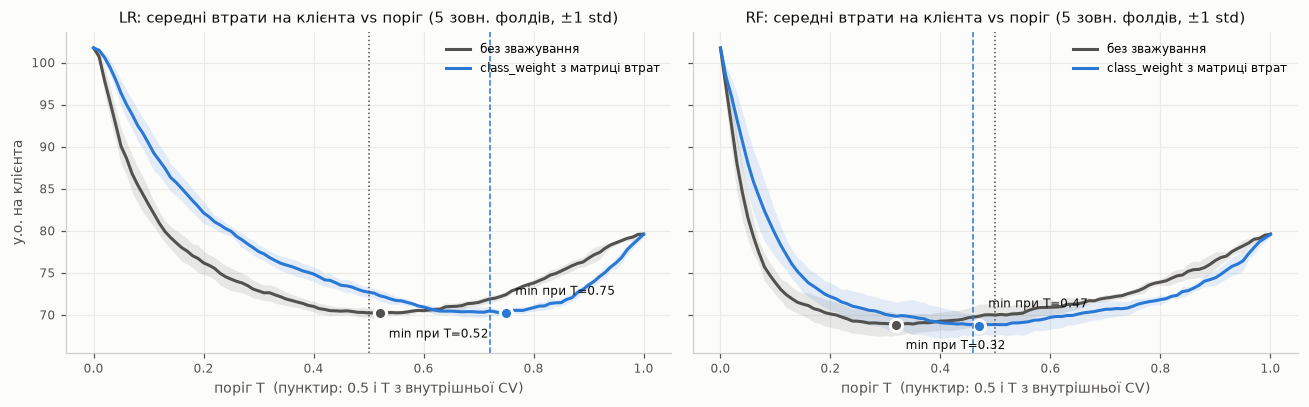

{'LR': 0.72, 'RF': 0.46}

— середній T, обраний на ВНУТРІШНІХ OOF-прогнозах (пунктир)

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, m in zip(axes, nested):
    P = nested[m]["predictions"]
    for (col, color, label), dy in zip([("p_baseline", MUTED, "без зважування"), ("p_weighted", ACCENT, "class_weight з матриці втрат")], (-16, 12)):
        curves = pd.concat([cost_curve(g.y, g[col], cm).assign(fold=f) for f, g in P.groupby("fold")])
        mean = curves.groupby("threshold").cost_per_customer.mean()
        std = curves.groupby("threshold").cost_per_customer.std()
        ax.plot(mean.index, mean.values, color=color, linewidth=2, label=label)
        ax.fill_between(mean.index, mean - std, mean + std, color=color, alpha=0.12, linewidth=0)
        t_opt = mean.idxmin()
        ax.plot([t_opt], [mean.min()], marker="o", markersize=8, color=color, markeredgecolor=SURFACE, markeredgewidth=2)
        ax.annotate(f"min при T={t_opt:.2f}", (t_opt, mean.min()), textcoords="offset points", xytext=(6, dy), fontsize=8, color=INK)
    T_cv = P.groupby("fold").T_weighted.first().mean()
    ax.axvline(0.5, color=MUTED, linestyle=":", linewidth=1)
    ax.axvline(T_cv, color=ACCENT, linestyle="--", linewidth=1)
    ax.set_title(f"{m}: середні втрати на клієнта vs поріг (5 зовн. фолдів, ±1 std)")
    ax.set_xlabel("поріг T  (пунктир: 0.5 і T з внутрішньої CV)"); ax.legend(loc="upper right", fontsize=8)
axes[0].set_ylabel("у.о. на клієнта")
fig.tight_layout(); fig.savefig(REPORTS / "lab3_cost_vs_threshold.png", bbox_inches="tight"); plt.show()
print({m: round(float(nested[m]["predictions"].groupby("fold").T_weighted.first().mean()), 3) for m in nested},
      "— середній T, обраний на ВНУТРІШНІХ OOF-прогнозах (пунктир)")

**Чому оптимальний поріг вищий за 0.5, а не нижчий за T\* = 0.30.** Формула T\* = w0/(w0+w1) правильна лише для **каліброваних**
імовірностей при справжній частці класів. У нашому конвеєрі імовірності «роздуті» двічі:
1. SMOTE до `sampling_strategy=0.5` множить шанси відтоку приблизно на 0.5 / (0.166/0.834) ≈ 2.5;
2. `class_weight` множить їх ще на w1/w0 = 118/50 ≈ 2.36.

Разом шанси відтоку зростають у ≈ 5.9 раза. Поріг T\* = 0.30 відповідає шансам 0.43; у «роздутій» шкалі це 0.43 × 5.9 ≈ 2.5, тобто
**T ≈ 0.72**. Для моделі без зважування (лише SMOTE): 0.43 × 2.5 ≈ 1.07 → **T ≈ 0.52**. Обрані на внутрішніх OOF-прогнозах пороги
(таблиця вище) близькі до цих оцінок. Отже зсув порогу вгору — не суперечність, а наслідок того, що SMOTE і ваги вже зсунули
імовірності вниз за класом «відтік», і поріг лише повертає рішення до бізнес-оптимуму. Без SMOTE і ваг оптимальний поріг був би < 0.5.


In [17]:
# Порівняння з бейзлайнами (REFORMS 5f): евристика ЛР1 на тих самих зовнішніх фолдах
from src.evaluation import heuristic_predict, total_cost
P = nested["LR"]["predictions"]
rows = []
for f, g in P.groupby("fold"):
    Xf = X.loc[g.row]
    h = heuristic_predict(Xf).to_numpy()
    rows.append({"fold": f, "approach": "0. Евристика ЛР1 (Tenure≤1 OR Complain)", "total_cost": total_cost(g.y, h, cm),
                 "cost_per_customer": total_cost(g.y, h, cm) / len(g), "F1": f1_score(g.y, h), "ROC_AUC": roc_auc_score(g.y, h)})
    rows.append({"fold": f, "approach": "00. Нікого не чіпати (ŷ=0)", "total_cost": total_cost(g.y, np.zeros(len(g)), cm),
                 "cost_per_customer": total_cost(g.y, np.zeros(len(g)), cm) / len(g), "F1": 0.0, "ROC_AUC": 0.5})
    rows.append({"fold": f, "approach": "000. Пропозиція всім (ŷ=1)", "total_cost": total_cost(g.y, np.ones(len(g)), cm),
                 "cost_per_customer": total_cost(g.y, np.ones(len(g)), cm) / len(g), "F1": f1_score(g.y, np.ones(len(g))), "ROC_AUC": 0.5})
base = pd.DataFrame(rows).groupby("approach")[["total_cost", "cost_per_customer", "F1", "ROC_AUC"]].agg(["mean", "std"]).round(3)
base.to_csv(REPORTS / "lab3_baselines.csv")
base

total_cost          cost_per_customer            F1        ROC_AUC       
                                              mean      std              mean    std   mean    std    mean    std
approach                                                                                                         
0. Евристика ЛР1 (Tenure≤1 OR Complain)    62183.2  704.376            76.599  0.892  0.486  0.021    0.76  0.019
00. Нікого не чіпати (ŷ=0)                 64608.0  262.907            79.586  0.299  0.000  0.000    0.50  0.000
000. Пропозиція всім (ŷ=1)                 82585.2  185.427           101.731  0.194  0.284  0.001    0.50  0.000

## 6. Статистична перевірка різниці «з витоком vs герметично» (п. 4.2, ч. 3)

McNemar (`mlxtend.evaluate.mcnemar`) порівнює **структуру помилок двох моделей на тих самих спостереженнях**.
Для цього обидві моделі прогнозують на тестовій частині розбиття ЛР2 (70/30, rs=42):
- **з витоком** — прогнози Експерименту 4 ЛР2 (LR), відтворені з тими самими seed (`src/legacy_lab2.py`);
  збіг ROC-AUC зі звітом ЛР2 (0.8599) доводить, що це той самий прогін, а не новий;
- **герметично** — конвеєр Кроку 3 (LR, дефолтні гіперпараметри), навчений на train-частині того самого розбиття;
  двома варіантами — без SMOTE (ізолює саме витік) і повний (з SMOTE).

Поріг 0.5. H₀: обидві моделі помиляються однаково часто (b = c у таблиці 2×2).


In [18]:
from src.legacy_lab2 import leaky_lr_proba, lab2_split, lab3_full_table, LAB2_LEAKY_AUC_LR
from src.evaluation import mcnemar_test
y_te, p_leak, ids_te = leaky_lr_proba()
print(f"Відтворений Експ. 4 ЛР2: ROC-AUC = {roc_auc_score(y_te, p_leak):.4f} (у звіті ЛР2: {LAB2_LEAKY_AUC_LR})")
_, df2, _, _, itr2, _ = lab2_split()
full = lab3_full_table().set_index(dc["id_column"])
tr2 = full.loc[df2.iloc[itr2][dc["id_column"]]].reset_index(); te2 = full.loc[ids_te].reset_index()
assert (te2[dc["target"]].to_numpy() == y_te).all()
mc_rows, probas_mc = [], {"Експ. 4 ЛР2 (витік)": p_leak}
for name, resample in [("Герметичний, без SMOTE", False), ("Герметичний, з SMOTE (Крок 3)", True)]:
    pipe = build_hermetic_pipeline(CONFIG["LR"], "LR", hc, resample=resample, memory=memory)
    pipe.fit(tr2.drop(columns=[dc["target"]]), tr2[dc["target"]])
    p = pipe.predict_proba(te2.drop(columns=[dc["target"]]))[:, 1]
    probas_mc[name] = p
    r = mcnemar_test(y_te, (p_leak >= 0.5).astype(int), (p >= 0.5).astype(int))
    mc_rows.append({"порівняння": f"витік vs {name}", "ROC-AUC витік": roc_auc_score(y_te, p_leak), "ROC-AUC герметично": roc_auc_score(y_te, p),
                    "правий лише 'витік' (b)": r["only_a_correct"], "правий лише герметичний (c)": r["only_b_correct"],
                    "χ² (з поправкою)": r["chi2"], "p-value": r["p_value"]})
mcnemar_df = pd.DataFrame(mc_rows)
mcnemar_df.round(4).to_csv(REPORTS / "lab3_mcnemar.csv", index=False)
mcnemar_df.round(4)

Відтворений Експ. 4 ЛР2: ROC-AUC = 0.8599 (у звіті ЛР2: 0.8599)

,порівняння,ROC-AUC витік,ROC-AUC герметично,правий лише 'витік' (b),правий лише герметичний (c),χ² (з поправкою),p-value
0,"витік vs Герметичний, без SMOTE",0.8599,0.8566,72,71,0.0000,1.0000
1,"витік vs Герметичний, з SMOTE (Крок 3)",0.8599,0.8556,101,67,6.4821,0.0109


**Інтерпретація** — див. `docs/lab3_report.md`, §6. Коротко: p-value < 0.05 означає, що різниця в *структурі помилок* не пояснюється
випадковістю розбиття. Але знак і величина різниці залежать від того, чи є SMOTE: SMOTE сам зсуває рішення на порозі 0.5,
тож саме для ізоляції витоку правильне порівняння — «без SMOTE». Різниця ROC-AUC тут невелика, і це узгоджується з ЛР2:
сегмент має ~160 категорій, тому витік WoE помірний.

## 7. Фінальна модель (для ЛР4–ЛР5)

Модель обирається за **середніми сумарними втратами** підходу «class_weight + поріг T» на зовнішніх фолдах (REFORMS 5d).
Потім Optuna запускається на всьому train, фінальний конвеєр навчається на всьому train, а поріг підбирається на OOF-прогнозах.
Holdout не використовується.


In [19]:
final_choice = table.xs("Cost-sensitive навчання + оптимальний поріг T", level=1)[("total_cost", "mean")].idxmin()
print("Обрана модель за мінімумом сумарних втрат:", final_choice)
# Навчання фінальної моделі — `python -m src.run_nested --final` (той самий критерій вибору; Optuna на всьому train,
# поріг на OOF-прогнозах усього train). Артефакт: models/lab3_final_pipeline.joblib; метадані:
meta = json.loads((REPORTS / "lab3_final_model.json").read_text(encoding="utf-8"))
assert meta["model"] == final_choice
meta

Обрана модель за мінімумом сумарних втрат:

RF

{'model': 'RF',
 'config': 'config/generated/config_rf_hermetic.yaml',
 'best_params': {'n_estimators': 281, 'max_depth': 11, 'k_neighbors': 5},
 'inner_cv_roc_auc': 0.91260858951695,
 'threshold': 0.46,
 'class_weight': {'0': 50.0, '1': 118.0},
 'cost_matrix': {'C00': 0, 'C01': 50, 'C10': 480, 'C11': 362},
 'selected_features': ['Tenure',
  'Complain',
  'PreferedOrderCat_Mobile Phone',
  'OrdersPerTenureMonth',
  'TenureStage',
  'Segment',
  'CouponUsed / Tenure',
  'DaySinceLastOrder / Tenure',
  'HourSpendOnApp / Tenure',
  'OrderCount / Tenure',
  'Tenure / OrderCount',
  'WarehouseToHome / Tenure',
  'NATURAL_LOGARITHM(Tenure)',
  'DaySinceLastOrder / Tenure__missing',
  'WarehouseToHome / Tenure__missing'],
 'train_rows': 4059,
 'data': 'data/processed/train.csv (DVC, dvc.lock)',
 'artifact': 'models/lab3_final_pipeline.joblib (не в git)'}